# Data Preparation

It is important to run this code block before working on the rest of the notebook. Check out the comments to help you understand what each step does.

Refer to the [VCQ code book](https://docs.google.com/document/d/1uYfUuUsPVQyD3puVvbIMjamYuVPr_f4gtJuSB5Wj-WA/edit) for questions that match the columns in the following dataset.

In [ ]:
# Step 1: Collect the original data into a DataFrame object
import pandas as pd
pd.options.display.float_format = '{:.2f}'.format
raw_df = pd.read_csv('https://raw.githubusercontent.com/qarnac/cs201/main/vcq_data_nan.csv')

# Step 2: Create a DataFrame object to hold the demographics columns
# Remove the demo_ prefix from column names
df = raw_df.filter(regex='^demo').copy()
df.columns = df.columns.str.removeprefix('demo_')

# Step 3: Create a DataFrame object to hold only columns from the family satisfaction
# Recode negatively worded questions and create a new column for average value
family_df = raw_df.filter(regex='^family').copy()
r_columns = ['family_stress', 'family_secrets', 'family_fight']
family_df[r_columns] = 7 - family_df[r_columns]
family_df['family_mean'] = family_df.mean(axis=1)

# Step 4: Create a DataFrame object to hold only columns from the deviance satisfaction
# Recode negatively worded questions and create a new column for average value
deviance_df = raw_df.filter(regex='^deviance').copy()
r_columns = ['deviance_play', 'deviance_cautious']
deviance_df[r_columns] = 7 - deviance_df[r_columns]
deviance_df['deviance_mean'] = deviance_df.mean(axis=1)

# Step 5: Add the average columns to the demographics dataset
df['family_satisfaction'] = family_df['family_mean']
df['deviance'] = deviance_df['deviance_mean']

# Step 6: replace numbers with text for categorical columns
gender_map = {1:'Male', 2:'Female', 3:'Other'}
df['gender'] = df['gender'].replace(gender_map)
yes_no_columns = ['relationshipstatus01', 'relationshipstatus02', 'children', 'employed01', 'employed02', 'employed04']
yes_no_map = {1:'Yes', 2:'No'}
df[yes_no_columns] = df[yes_no_columns].replace(yes_no_map)
class_labels = ['First-year', 'Sophomore', 'Junior', 'Senior']
class_bins = [0, 1, 2, 3, 4]
df['classstanding'] = pd.cut(df['classstanding'],
                             bins=class_bins,
                             labels=class_labels,
                             right=True)
politics_labels = ['conservative', 'moderate', 'liberal']
politics_bins = [0, 2, 4, 6]
df['politics'] = pd.cut(df['politics'],
                             bins=politics_bins,
                             labels=politics_labels,
                             right=True)

religion_labels = ['Yes', 'No']
religion_bins = [0, 3, 6]
df['religion'] = pd.cut(df['religion'],
                             bins=religion_bins,
                             labels=religion_labels,
                             right=True)


df.head(10)


,gender,age,relationshipstatus01,children,classstanding,units,gpa,employed01,employed02,employed03,incomehousehold,incomepersonal,politics,religion,relationshipstatus02,employed04,family_satisfaction,deviance
0,Male,19.00,Yes,No,Sophomore,15.00,3.15,Yes,Yes,45.00,60000.00,16000.00,NaN,No,Yes,Yes,4.29,3.62
1,Female,26.00,No,No,Junior,14.00,3.30,Yes,Yes,35.00,27000.00,27000.00,moderate,No,No,Yes,4.86,3.12
2,Male,NaN,Yes,No,Junior,15.00,3.11,No,No,NaN,6000.00,2000.00,moderate,Yes,Yes,NaN,5.14,3.12
3,Female,NaN,Yes,No,Sophomore,17.00,3.40,No,No,NaN,NaN,NaN,moderate,No,Yes,No,4.71,3.50
4,Female,19.00,Yes,No,Sophomore,13.00,3.00,No,No,NaN,NaN,NaN,moderate,Yes,Yes,No,4.43,3.62
5,Female,24.00,Yes,No,Junior,16.00,3.00,Yes,Yes,45.00,25000.00,NaN,NaN,Yes,Yes,Yes,3.71,3.12
6,Male,20.00,No,No,Junior,17.00,3.25,Yes,Yes,20.00,NaN,9000.00,conservative,Yes,No,Yes,4.71,2.75
7,Female,21.00,Yes,No,Senior,15.00,2.33,Yes,Yes,26.00,60000.00,14400.00,liberal,Yes,Yes,Yes,4.71,3.75
8,Female,20.00,No,No,Junior,12.00,3.00,Yes,Yes,30.00,NaN,NaN,moderate,Yes,No,Yes,5.00,3.38
9,Male,27.00,No,No,Senior,15.00,3.47,Yes,Yes,25.00,50000.00,30000.00,liberal,No,No,Yes,4.00,3.12


# The groupby function

The `groupby()` function in pandas is used to split your data into groups based on the values in one or more columns, and then apply a calculation (like mean, count, sum) to each group. Think of it like sorting your data into labeled bins, and then doing math inside each bin.

For example, the following call to the `groupby` function groups values in the `'family_satisfaction'` column based on `'gender'` and then **count** the number of respondents within each gender.

In [ ]:
gender_counts_family = df.groupby('gender')['family_satisfaction'].count()
gender_counts_family

,family_satisfaction
gender,
Female,362
Male,176
Other,4


We can see that out of the 542 students who answered the family satisfaction section of the survey, 362 of them were female, 176 were male, and 4 answered other.

The following call to the groupby function groups values in the 'family_satisfaction' column based on 'gender' and the calculate the average family satisfaction within each gender.

In [ ]:
gender_average_family = df.groupby('gender')['family_satisfaction'].mean()
gender_average_family

,family_satisfaction
gender,
Female,4.36
Male,4.26
Other,4.21


We can see that the average family satisfaction for female was a bit higher than the average family satisfaction for male. The average family satisfaction for other was the lowest.

Using the same approach, we can also find out the standard deviation of family satisfaction within each gender.

In [ ]:
gender_std_family = df.groupby('gender')['family_satisfaction'].std()
gender_std_family

,family_satisfaction
gender,
Female,0.76
Male,0.82
Other,0.97


We can see that female has the least variation within their group while other has the highest variation within their group.

## Practice

Pick another categorical column and apply the count, mean, and std function for family_satisfaction using as many/few code block as needed.

In [ ]:
# code block

**Add a text block** to communicate what you learned from the results of count, mean, and std of the above exercise.

# The agg function

The `agg()` function stands for *aggregate*, and it lets you apply multiple statistics functions (like mean, count, std, min, max, median, etc.) to your grouped data.

In [ ]:
gender_summary_family = df.groupby('gender', observed=True)['family_satisfaction'].agg(['count', 'mean', 'std', 'min', 'max', 'median'])
gender_summary_family

,count,mean,std,min,max,median
gender,,,,,,
Female,362,4.36,0.76,1.00,6.00,4.43
Male,176,4.26,0.82,2.00,5.86,4.29
Other,4,4.21,0.97,3.14,5.43,4.14


From the above results, we can see several statistics in one table format. For example,
*  362 female students and 176 male students answered the family satisfaction section.
*  Only 4 students marked other for gender on their survey. With such a small number, it would be hard to generalize any findings for this group.
*  The lowest level of family satisfaction for female students was 1 while the the highest level was 6.
*  The median and average family satisfaction for female students were slightly higher than those for male students. Meanwhile, responses from female students varied slightly less than responses from male students.


## Practice

In [ ]:
# Pick a categorical column and use the agg function to determine
# the count, mean, and std for deviance by respective categories

**Add a text block** to communicate what you learned from the above results.

# Pivot Tables

A pivot table is a powerful tool used to summarize, organize, and analyze data, especially when working with large datasets. It allows you to group data by multiple categories and compute statistics for each sub-group.

A `pivot_table` function call typically specifies three parameters:

*  **values**: This identifies the numeric column(s) on which we want to perform analyses.
*  **index**: This specifies the groupings that will be performed.
*  **aggfunc**: This specifies the analysis to be performed.

In the following code block, we pivot the `family_satisfaction` column using the `gender` column to perform the count action.

In [ ]:
pivot_by_gender = df.pivot_table(values='family_satisfaction',
              index='gender',
              aggfunc = 'count')
pivot_by_gender

,family_satisfaction
gender,
Female,362
Male,176
Other,4


The above pivot table generates similar results as the use of groupby function.

For each of the three parameters, we are allowed to specify a list.

The following block shows how we can specify two numeric columns to be analyzed: 'family_satisfaction' and 'deviance'.

In [ ]:
pivot_by_gender_class = df.pivot_table(values=['family_satisfaction', 'deviance'],
                        index='gender',
                        aggfunc = 'mean',
                        observed=True)
pivot_by_gender_class

,deviance,family_satisfaction
gender,,
Female,3.14,4.36
Male,3.44,4.26
Other,3.50,4.21


From the above pivot table, we can see that
*  average deviance for female is lower than male
*  average family satisfaction for female is higher than male

The following example shows how we can ask the analyses be grouped by two categorical columns: first by 'gender' and then by 'classstanding' within each gender.

In [ ]:
pivot_by_gender_class = df.pivot_table(values=['family_satisfaction', 'deviance'],
                        index=['gender', 'classstanding'],
                        aggfunc = 'mean',
                        observed=True)
pivot_by_gender_class

deviance  family_satisfaction
gender classstanding                               
Female First-year         2.98                 4.55
       Sophomore          3.16                 4.25
       Junior             3.11                 4.37
       Senior             3.27                 4.53
Male   First-year         3.38                 4.35
       Sophomore          3.26                 4.21
       Junior             3.55                 4.25
       Senior             3.48                 4.32
Other  First-year         4.38                 3.86
       Sophomore          4.12                 3.14
       Junior             2.75                 4.93

Here are a few things we can observe from the above pivot table:

*  For female students, first year respondents had lowest average deviance and highest average family satisfaction.
*  For male students, sophomore respondents had lowest average deviance and lowest average family satisfaction.
*  Female students had higher average family satisfaction than male in every class standing.

The following code block shows that we can also perform multiple analyses: mean and standard deviation.

In [ ]:
pivot_by_gender_class = df.pivot_table(values=['family_satisfaction', 'deviance'],
                        index=['gender', 'classstanding'],
                        aggfunc = ['mean', 'std'],
                        observed=True)
pivot_by_gender_class

mean                          std                    
                     deviance family_satisfaction deviance family_satisfaction
gender classstanding                                                          
Female First-year        2.98                4.55     0.60                0.70
       Sophomore         3.16                4.25     0.70                0.80
       Junior            3.11                4.37     0.66                0.72
       Senior            3.27                4.53     0.66                0.80
Male   First-year        3.38                4.35     0.76                0.60
       Sophomore         3.26                4.21     0.71                0.88
       Junior            3.55                4.25     0.77                0.81
       Senior            3.48                4.32     0.60                0.84
Other  First-year        4.38                3.86      NaN                 NaN
       Sophomore         4.12                3.14      NaN                 NaN
       Junior            2.75                4.93     0.18                0.71

As we can see from the above result, performing multiple analyses on multiple columns using multiple grouping can make the resulting pivot table complex and hard to read.

## Practice

In [ ]:
# Create a pivot table on average deviance using two demographics columns.
# At least one of the columns must be different from gender or classstanding.



In [ ]:
# Create a pivot table of your choice that's different from what have been done.



**Add a text block** to communicate your findings about the students based on the above results.

# The reset_index function

You might have noticed the difference between the headings for categories and the headings for the stats. This is because the categories used in groupby and pivot_table are considered row indices not columns. The `reset_index` function helps convert row indices into columns. This is illustrated by the following code block.

In [ ]:
pivot_by_gender = pivot_by_gender.reset_index()
pivot_by_gender

,gender,family_satisfaction
0,Female,362
1,Male,176
2,Other,4


# The sns.barplot function

The `sns.barplot` function provides a nice tool to geneate bar charts. Similar to the other `seaborn` function,

*  The `data` parameter identifies the dataset needed to generate the bar chart.
*  The `x` parameter identifies the column for the x-axis.
*  The `y` parameter indicates the column for the y-axis.
*  The `hue` parameter separate groups within the x-axis.

We need to specify other settings of the figure, e.g. `figsize`, `title`, `legend`, outside `sns.barplot`. In the following example, we use plt,legend to move the legend box outside of the bar chart area to make it easier to read.
*  The `bbox_to_anchor` parameter specifies two things. The first one is the relative x positon where 0 is the left side of the bar chart and 1 is the right side of the bar chart. Therefore, 1.05 is a bit right of the bar chart. The second one is the relative y position where 0 is the bottom of the bar chart and 1 is the top of the bar chart. Therefore, `(1.05, 1)` indicates a bit to the right of the barchart and exactly on the top of the bar chart.
*  The `loc` parameter specifies which corner of the legend box we would anchor.

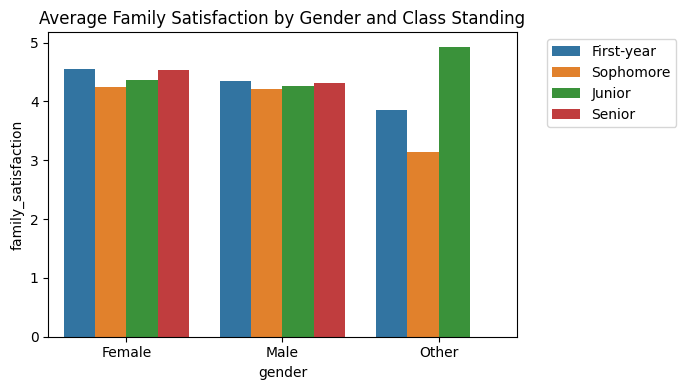

In [ ]:
# Data preparation
family_by_gender_class = df.pivot_table(values='family_satisfaction',
                                        index=['gender', 'classstanding'],
                                        aggfunc='mean',
                                        observed=True).reset_index()

# create the bar chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
plt.title('Average Family Satisfaction by Gender and Class Standing')

sns.barplot(data = family_by_gender_class,
            x = 'gender',
            y = 'family_satisfaction',
            hue = 'classstanding')

plt.legend(bbox_to_anchor=(1.05, 1),  # move legend outside
    loc='upper left'    # specify which corner of the legend box for anchor
)
plt.tight_layout()
plt.show()

The above bar chart allows us to compare average family satisfaction among different class standing for each gender. Here are a few things we can observe:

*  Within each gender group, average family satisfaction is the lowest for sophomore students.
*  For Female students, first year student reported the highest level of family satisfaction.
*  Gaps of familiy satisfaction among different class standings is higher for female than male.

When we switch the x and hue parameters in sns.barplot, we can visualize the difference among genders for the same class standing.

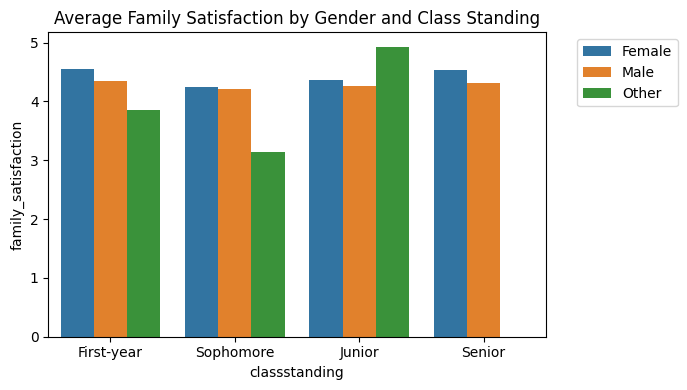

In [ ]:
# create the bar chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
plt.title('Average Family Satisfaction by Gender and Class Standing')

sns.barplot(data = family_by_gender_class,
            x = 'classstanding',
            y = 'family_satisfaction',
            hue = 'gender')

plt.legend(bbox_to_anchor=(1.05, 1),  # move legend outside
    loc='upper left'    # specify which corner of the legend box for anchor
)
plt.tight_layout()
plt.show()

Here are a few things we can observe from the above visualization.

*  Average family satisfaction is higher for female students than male students across all class standings.
*  The gap is higher for first-year and senior compared to sophomore and junior.

## Practice

In [ ]:
# Choose two categorical columns to create a bar chart that help you compare
# average deviance between groups and subgroups. You'll need to create a dataset first


Add a markdown text block to explain what you learn from the bar chart.